# Análisis exploratorio — Reseñas de videojuegos IGN

**Fuente:** tabla `public.ign_games` en Supabase (PostgreSQL), cargada desde `IGN games from best to worst (1).csv`.

**Contenido:**
0. Limpieza de datos
1. Análisis univariado
2. Análisis bivariado
3. Análisis gráfico

## Conexión a Supabase y carga de datos

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()  # lee DIRECT_URL desde el archivo .env
engine = create_engine(os.environ["DIRECT_URL"])

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", 20)

df_raw = pd.read_sql("SELECT * FROM public.ign_games", engine)
print(df_raw.shape)
df_raw.head()

(18625, 8)


,title,score,score_phrase,platform,genre,release_year,release_month,release_day
0,Checkered Flag,10.0,Masterpiece,Lynx,Racing,1999,7,6
1,Chrono Trigger,10.0,Masterpiece,Wii,"Action, RPG",2011,5,25
2,Dragon Warrior III,10.0,Masterpiece,Game Boy Color,RPG,2001,7,20
3,Grand Theft Auto IV,10.0,Masterpiece,Xbox 360,"Action, Adventure",2008,4,25
4,Grand Theft Auto IV,10.0,Masterpiece,PlayStation 3,"Action, Adventure",2008,4,25


In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 18625 entries, 0 to 18624
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   title          18625 non-null  str    
 1   score          18625 non-null  float64
 2   score_phrase   18625 non-null  str    
 3   platform       18625 non-null  str    
 4   genre          18589 non-null  str    
 5   release_year   18625 non-null  int64  
 6   release_month  18625 non-null  int64  
 7   release_day    18625 non-null  int64  
dtypes: float64(1), int64(3), str(4)
memory usage: 1.1 MB


---
## 0. Limpieza de datos

Revisamos: tipos de datos, valores nulos, duplicados, espacios sobrantes, fechas inválidas y valores atípicos.

In [3]:
df = df_raw.copy()
print("Nulos por columna:")
print(df.isna().sum())
print("\nFilas duplicadas exactas:", df.duplicated().sum())

Nulos por columna:
title             0
score             0
score_phrase      0
platform          0
genre            36
release_year      0
release_month     0
release_day       0
dtype: int64

Filas duplicadas exactas: 48


### 0.1 Espacios en blanco en columnas de texto

In [4]:
cols_texto = ["title", "score_phrase", "platform", "genre"]
for c in cols_texto:
    df[c] = df[c].str.strip()
df[cols_texto].describe()

,title,score_phrase,platform,genre
count,18625,18625,18625,18589
unique,12589,11,59,112
top,Madden NFL 07,Great,PC,Action
freq,10,4773,3370,3797


### 0.2 Eliminar duplicados

In [5]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {antes - len(df)}  ->  filas restantes: {len(df)}")

Duplicados eliminados: 48  ->  filas restantes: 18577


### 0.3 Valores nulos en `genre`
Son muy pocos; se imputan con la etiqueta `Desconocido` para no perder la reseña.

In [6]:
print("Juegos sin género:", df["genre"].isna().sum())
df["genre"] = df["genre"].fillna("Desconocido")

Juegos sin género: 36


### 0.4 Fechas: validación y columna `fecha`

In [7]:
df["fecha"] = pd.to_datetime(
    dict(year=df.release_year, month=df.release_month, day=df.release_day), errors="coerce"
)
print("Fechas inválidas:", df["fecha"].isna().sum())
df["release_year"].value_counts().sort_index().head()

Fechas inválidas: 0


release_year
1970      1
1996    135
1997    205
1998    339
1999    770
Name: count, dtype: int64

Aparece un registro en **1970**, muy lejos del resto (IGN empieza a reseñar en 1996). Es un error de captura, así que lo eliminamos.

In [8]:
display(df[df.release_year < 1996])
df = df[df.release_year >= 1996].reset_index(drop=True)

,title,score,score_phrase,platform,genre,release_year,release_month,release_day,fecha
3674,The Walking Dead: The Game -- Episode 1: A New...,8.5,Great,Xbox 360,Adventure,1970,1,1,1970-01-01


### 0.5 Validar rango de `score` y coherencia con `score_phrase`

In [9]:
print("Score fuera de [0, 10]:", (~df.score.between(0, 10)).sum())
df.groupby("score_phrase")["score"].agg(["min", "max", "count"]).sort_values("min")

Score fuera de [0, 10]: 0


,min,max,count
score_phrase,,,
Disaster,0.5,0.8,3
Unbearable,1.0,1.9,71
Painful,2.0,2.9,339
Awful,3.0,3.9,663
Bad,4.0,4.9,1266
Mediocre,5.0,5.9,1956
Okay,6.0,6.9,2937
Good,7.0,7.9,4723
Great,8.0,8.9,4762


Cada frase corresponde a un rango fijo de puntaje, sin solapamientos: la columna es consistente. La convertimos a **categoría ordenada**.

In [10]:
orden_frases = ["Disaster", "Unbearable", "Painful", "Awful", "Bad", "Mediocre",
                "Okay", "Good", "Great", "Amazing", "Masterpiece"]
df["score_phrase"] = pd.Categorical(df["score_phrase"], categories=orden_frases, ordered=True)

### 0.6 Variables derivadas
- `genero_principal`: primer género listado (`"Action, RPG"` → `Action`), reduce 112 combinaciones a pocas categorías.
- `num_generos`: cuántos géneros tiene el juego.
- `periodo`: tramo de años.

In [11]:
df["genero_principal"] = df["genre"].str.split(",").str[0].str.strip()
df["num_generos"] = df["genre"].str.count(",") + 1
df["periodo"] = pd.cut(df.release_year, bins=[1995, 2000, 2005, 2010, 2016],
                       labels=["1996-2000", "2001-2005", "2006-2010", "2011-2016"])
print("Géneros originales:", df.genre.nunique(), " -> géneros principales:", df.genero_principal.nunique())
print("Plataformas:", df.platform.nunique())
print("Dataset limpio:", df.shape)
df.head()

Géneros originales: 113  -> géneros principales: 31
Plataformas: 59
Dataset limpio: (18576, 12)


,title,score,score_phrase,platform,genre,release_year,release_month,release_day,fecha,genero_principal,num_generos,periodo
0,Checkered Flag,10.0,Masterpiece,Lynx,Racing,1999,7,6,1999-07-06,Racing,1,1996-2000
1,Chrono Trigger,10.0,Masterpiece,Wii,"Action, RPG",2011,5,25,2011-05-25,Action,2,2011-2016
2,Dragon Warrior III,10.0,Masterpiece,Game Boy Color,RPG,2001,7,20,2001-07-20,RPG,1,2001-2005
3,Grand Theft Auto IV,10.0,Masterpiece,Xbox 360,"Action, Adventure",2008,4,25,2008-04-25,Action,2,2006-2010
4,Grand Theft Auto IV,10.0,Masterpiece,PlayStation 3,"Action, Adventure",2008,4,25,2008-04-25,Action,2,2006-2010


**Resumen de limpieza:** se quitaron espacios, se eliminaron 48 duplicados, se imputaron 36 géneros nulos, se descartó 1 registro con año atípico (1970), se validaron fechas y rangos de puntaje, y se crearon variables derivadas.

---
## 1. Análisis univariado

### 1.1 `score` (puntaje, variable numérica)

In [12]:
s = df["score"]
resumen = pd.Series({
    "media": s.mean(), "mediana": s.median(), "moda": s.mode()[0],
    "desv. estándar": s.std(), "mínimo": s.min(), "máximo": s.max(),
    "Q1": s.quantile(.25), "Q3": s.quantile(.75), "rango IQR": s.quantile(.75) - s.quantile(.25),
    "asimetría": s.skew(), "curtosis": s.kurt(),
}).round(2)
resumen

media              6.95
mediana            7.30
moda               8.00
desv. estándar     1.71
mínimo             0.50
máximo            10.00
Q1                 6.00
Q3                 8.20
rango IQR          2.20
asimetría         -0.85
curtosis           0.29
dtype: float64

In [13]:
q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
atipicos = df[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]
print(f"Atípicos por IQR (score < {q1 - 1.5*iqr:.2f}): {len(atipicos)} juegos ({len(atipicos)/len(df):.1%})")

Atípicos por IQR (score < 2.70): 389 juegos (2.1%)


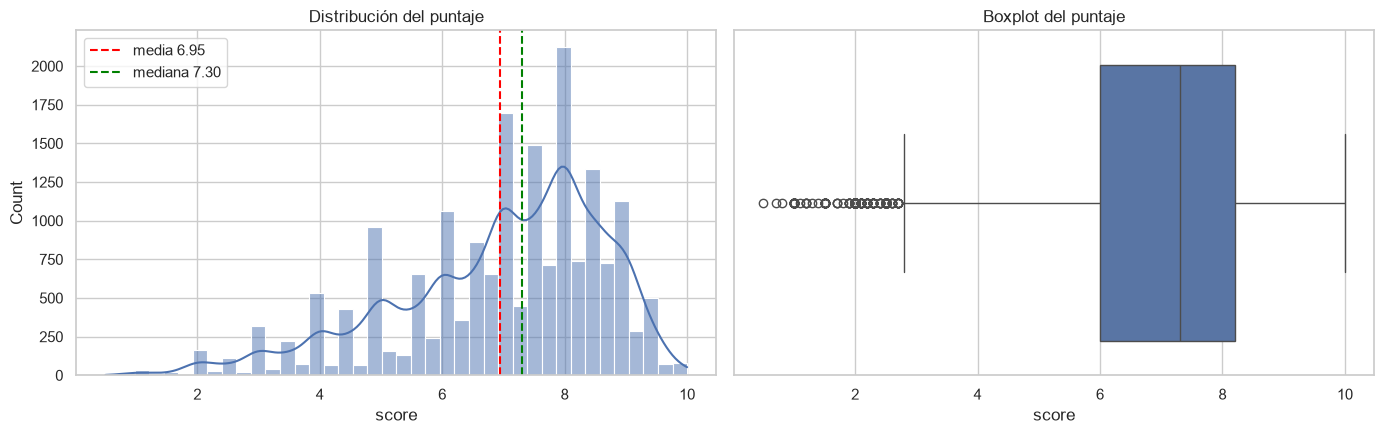

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(s, bins=40, kde=True, ax=ax[0], color="#4C72B0")
ax[0].axvline(s.mean(), color="red", ls="--", label=f"media {s.mean():.2f}")
ax[0].axvline(s.median(), color="green", ls="--", label=f"mediana {s.median():.2f}")
ax[0].legend(); ax[0].set_title("Distribución del puntaje")
sns.boxplot(x=s, ax=ax[1], color="#4C72B0"); ax[1].set_title("Boxplot del puntaje")
plt.tight_layout(); plt.show()

### 1.2 `score_phrase` (categórica ordinal)

In [15]:
frec = df["score_phrase"].value_counts().reindex(orden_frases)
tabla = pd.DataFrame({"frecuencia": frec, "porcentaje": (frec / frec.sum() * 100).round(2)})
tabla

,frecuencia,porcentaje
score_phrase,,
Disaster,3,0.02
Unbearable,71,0.38
Painful,339,1.82
Awful,663,3.57
Bad,1266,6.82
Mediocre,1956,10.53
Okay,2937,15.81
Good,4723,25.43
Great,4762,25.64


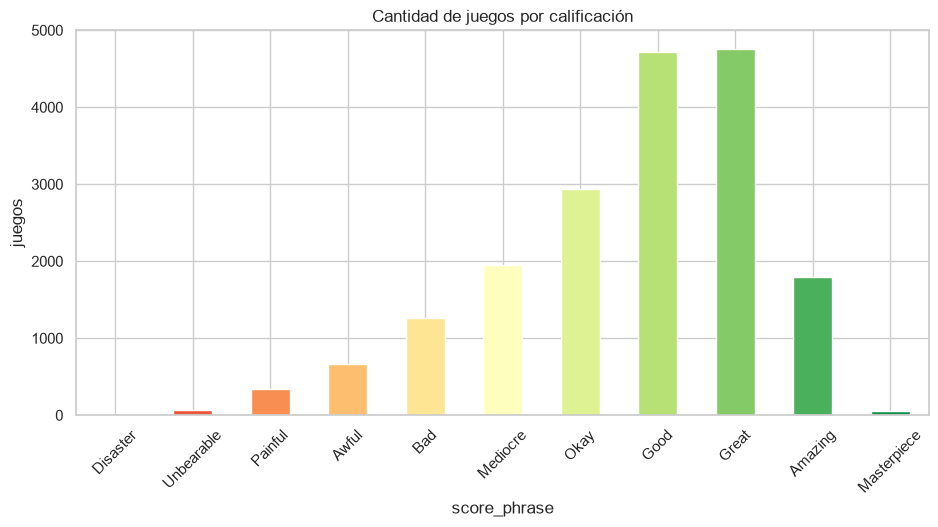

In [16]:
ax = frec.plot(kind="bar", color=sns.color_palette("RdYlGn", len(frec)))
ax.set_title("Cantidad de juegos por calificación"); ax.set_ylabel("juegos"); plt.xticks(rotation=45); plt.show()

### 1.3 `platform`

In [17]:
plat = df["platform"].value_counts()
print("Plataformas distintas:", len(plat))
print(f"Top 10 concentra el {plat.head(10).sum()/plat.sum():.1%} de las reseñas")
plat.head(15).to_frame("juegos")

Plataformas distintas: 59
Top 10 concentra el 75.1% de las reseñas


,juegos
platform,
PC,3365
PlayStation 2,1685
Xbox 360,1628
Wii,1363
PlayStation 3,1352
Nintendo DS,1042
PlayStation,938
Wireless,910
iPhone,841


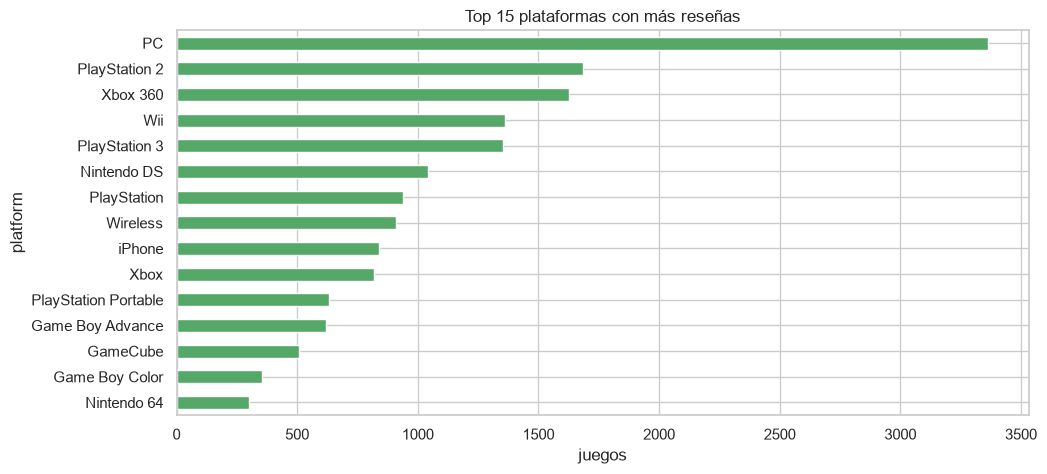

In [18]:
plat.head(15).sort_values().plot(kind="barh", color="#55A868")
plt.title("Top 15 plataformas con más reseñas"); plt.xlabel("juegos"); plt.show()

### 1.4 `genero_principal`

In [19]:
gen = df["genero_principal"].value_counts()
(gen / gen.sum() * 100).round(2).head(15).to_frame("% de juegos")

,% de juegos
genero_principal,
Action,26.97
Sports,11.72
Shooter,8.81
Racing,7.87
Adventure,6.42
Strategy,6.18
Puzzle,5.58
RPG,5.35
Platformer,4.51


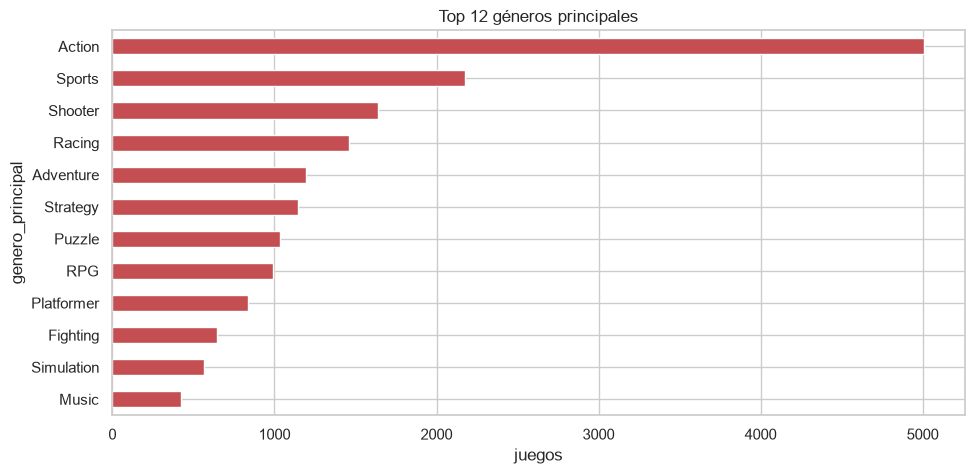

In [20]:
gen.head(12).sort_values().plot(kind="barh", color="#C44E52")
plt.title("Top 12 géneros principales"); plt.xlabel("juegos"); plt.show()

### 1.5 `release_year` y `release_month`

Año con más reseñas: 2008 (1911 juegos)


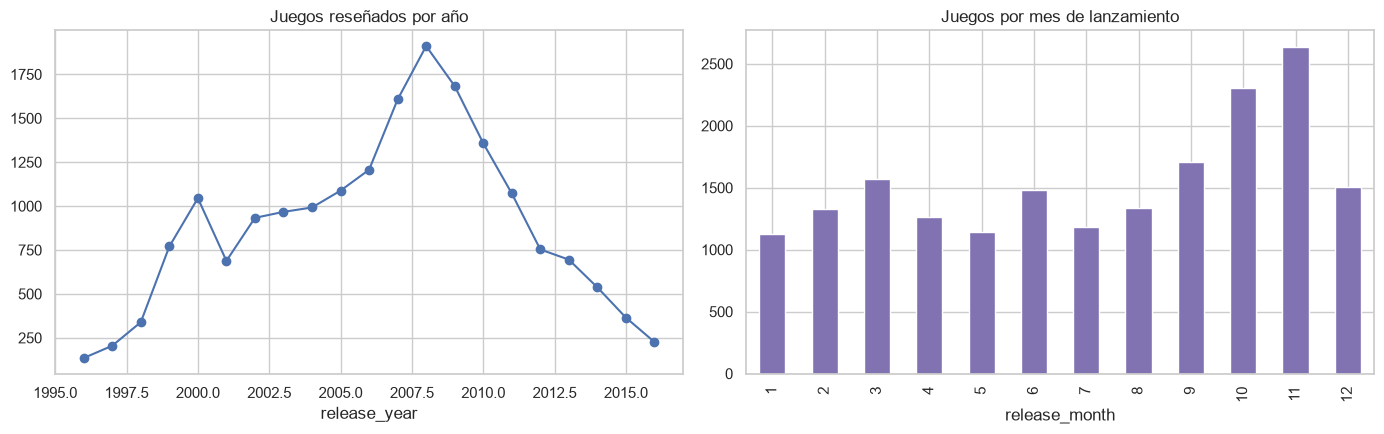

Mes con más lanzamientos: 11


In [21]:
anio = df["release_year"].value_counts().sort_index()
print("Año con más reseñas:", anio.idxmax(), f"({anio.max()} juegos)")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
anio.plot(marker="o", ax=ax[0]); ax[0].set_title("Juegos reseñados por año")
mes = df["release_month"].value_counts().sort_index()
mes.plot(kind="bar", ax=ax[1], color="#8172B2"); ax[1].set_title("Juegos por mes de lanzamiento")
plt.tight_layout(); plt.show()
print("Mes con más lanzamientos:", mes.idxmax())

### Conclusiones del análisis univariado

- **Puntaje (`score`)**: media de **6.95** y mediana de **7.30**; la moda es **8.0**. La asimetría negativa (**-0.85**) indica que la mayoría de juegos recibe notas altas y hay una cola larga hacia notas bajas. El 50 % central está entre 6.0 y 8.2.
- **Atípicos**: 389 juegos (2.1 %) tienen menos de 2.7 puntos; son reseñas reales muy negativas, no errores, así que se conservan.
- **Calificaciones**: *Great* (25.6 %) y *Good* (25.4 %) concentran más de la mitad de las reseñas. Las notas extremas son raras: solo 55 *Masterpiece* (0.3 %) y 3 *Disaster*.
- **Plataformas**: hay 59, pero el top 10 concentra el **75 %** de las reseñas. **PC** domina con 3 365 juegos, casi el doble que la siguiente (PlayStation 2).
- **Géneros**: *Action* es el género principal del **27 %** de los juegos, seguido de *Sports* (11.7 %) y *Shooter* (8.8 %).
- **Tiempo**: las reseñas crecen hasta un pico en **2008** (1 911 juegos) y luego caen. **Noviembre** es el mes con más lanzamientos (temporada navideña).

---
## 2. Análisis bivariado

### 2.1 `score` vs `release_year` (numérica – numérica)

In [22]:
r_pearson = df["score"].corr(df["release_year"])
r_spearman = df["score"].corr(df["release_year"], method="spearman")
print(f"Correlación de Pearson:  {r_pearson:.3f}")
print(f"Correlación de Spearman: {r_spearman:.3f}")
por_anio = df.groupby("release_year")["score"].agg(["mean", "median", "count"]).round(2)
por_anio

Correlación de Pearson:  0.063
Correlación de Spearman: 0.047


,mean,median,count
release_year,,,
1996,6.13,6.5,135
1997,6.57,7.0,205
1998,6.93,7.2,339
1999,6.98,7.3,770
2000,6.69,7.0,1045
2001,7.12,7.5,688
2002,6.98,7.5,933
2003,7.20,7.6,967
2004,7.17,7.5,992


### 2.2 Matriz de correlación entre variables numéricas

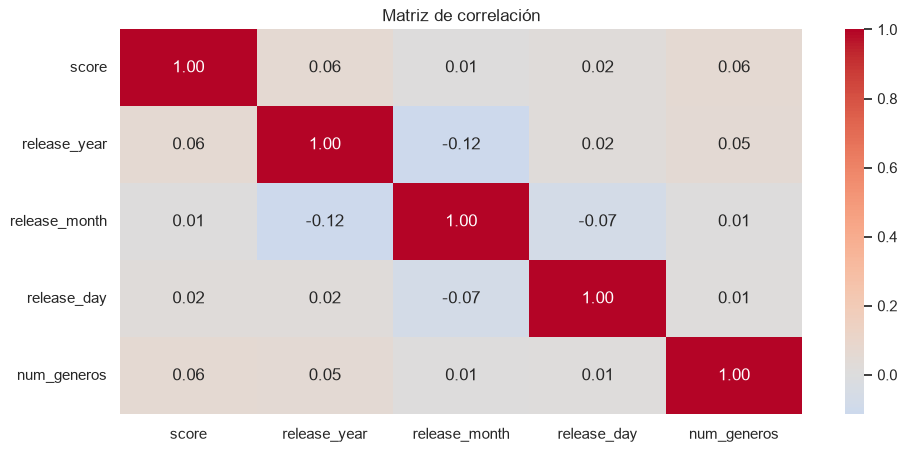

In [23]:
num = df[["score", "release_year", "release_month", "release_day", "num_generos"]]
corr = num.corr().round(3)
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matriz de correlación"); plt.show()

### 2.3 `score` vs `genero_principal` (numérica – categórica)

In [24]:
top_gen = gen[gen >= 100].index
g = (df[df.genero_principal.isin(top_gen)]
     .groupby("genero_principal")["score"].agg(["mean", "median", "std", "count"])
     .round(2).sort_values("mean", ascending=False))
g

,mean,median,std,count
genero_principal,,,,
RPG,7.57,7.90,1.42,994
Strategy,7.29,7.60,1.46,1148
Platformer,7.22,7.50,1.62,838
Shooter,7.14,7.50,1.75,1637
Puzzle,7.10,7.50,1.54,1037
Wrestling,7.06,7.45,1.59,134
Sports,7.04,7.50,1.83,2178
Music,6.99,7.50,1.76,421
Fighting,6.99,7.40,1.76,646


### 2.4 `score` vs `platform` (plataformas con ≥ 200 reseñas)

In [25]:
top_plat = plat[plat >= 200].index
p = (df[df.platform.isin(top_plat)]
     .groupby("platform")["score"].agg(["mean", "median", "count"])
     .round(2).sort_values("mean", ascending=False))
p

,mean,median,count
platform,,,
PlayStation 4,7.66,8.0,277
Xbox One,7.66,8.0,208
Dreamcast,7.37,8.0,286
Nintendo 3DS,7.32,7.6,224
iPhone,7.29,7.5,841
Xbox,7.20,7.7,819
PlayStation 3,7.19,7.5,1352
Wireless,7.18,7.5,910
PC,7.15,7.5,3365


### 2.5 `score` vs `num_generos`

In [26]:
df.groupby("num_generos")["score"].agg(["mean", "count"]).round(2)

,mean,count
num_generos,,
1,6.91,15965
2,7.21,2611


### 2.6 `genero_principal` vs `periodo` (categórica – categórica)

In [27]:
ct = pd.crosstab(df[df.genero_principal.isin(gen.head(8).index)].genero_principal,
                 df.periodo, normalize="columns").mul(100).round(1)
ct

periodo,1996-2000,2001-2005,2006-2010,2011-2016
genero_principal,,,,
Action,33.2,34.4,35.2,32.6
Adventure,5.1,4.8,8.1,14.6
Puzzle,5.7,3.6,10.0,6.6
RPG,5.8,5.3,6.1,10.7
Racing,17.2,12.4,8.4,5.1
Shooter,3.8,11.3,11.4,15.4
Sports,20.9,19.1,13.5,8.1
Strategy,8.3,9.1,7.3,6.9


### 2.7 `score_phrase` vs `periodo`

In [28]:
pd.crosstab(df.score_phrase, df.periodo, normalize="columns").mul(100).round(1)

periodo,1996-2000,2001-2005,2006-2010,2011-2016
score_phrase,,,,
Disaster,0.0,0.0,0.0,0.0
Unbearable,0.6,0.4,0.5,0.1
Painful,2.5,1.6,2.2,0.8
Awful,5.1,3.2,4.1,1.8
Bad,7.8,5.3,8.3,4.9
Mediocre,10.7,9.1,12.1,8.8
Okay,14.8,15.4,17.1,14.3
Good,22.4,24.8,27.6,23.7
Great,24.7,29.3,22.3,28.7


### Conclusiones del análisis bivariado

- **Año vs puntaje**: la correlación lineal es casi nula (Pearson **0.06**), pero la media por año no es plana: sube hasta ~7.2 en 2003-2005, cae a su mínimo en **2008 (6.45)** —el año con más reseñas— y desde 2011 sube hasta **7.66 en 2015**. La relación existe pero no es lineal.
- **Género vs puntaje**: *RPG* (7.57) y *Strategy* (7.29) son los géneros mejor valorados; *Party* (5.85) y *Hunting* (5.67) los peores. *Action*, el más numeroso, queda por debajo de la media (6.81).
- **Plataforma vs puntaje**: las consolas más recientes (**PS4 y Xbox One, 7.66**) tienen las notas más altas; **Wii, Nintendo DS y Game Boy Color** (~6.2-6.3) las más bajas, probablemente por la gran cantidad de juegos casuales o de baja calidad en esas plataformas.
- **Nº de géneros vs puntaje**: los juegos con 2 géneros promedian **7.21** frente a **6.91** de los de un solo género.
- **Género vs periodo**: *Sports* pasa del 20.9 % al 8.1 % y *Racing* del 17.2 % al 5.1 %, mientras que *Shooter* (3.8 % → 15.4 %), *Adventure* (5.1 % → 14.6 %) y *RPG* (5.8 % → 10.7 %) ganan peso.
- **Calificación vs periodo**: en 2011-2016 el 16.4 % de los juegos es *Amazing*, frente al 5.6 % de 2006-2010.

---
## 3. Análisis gráfico

### 3.1 Puntaje promedio y cantidad de reseñas por año

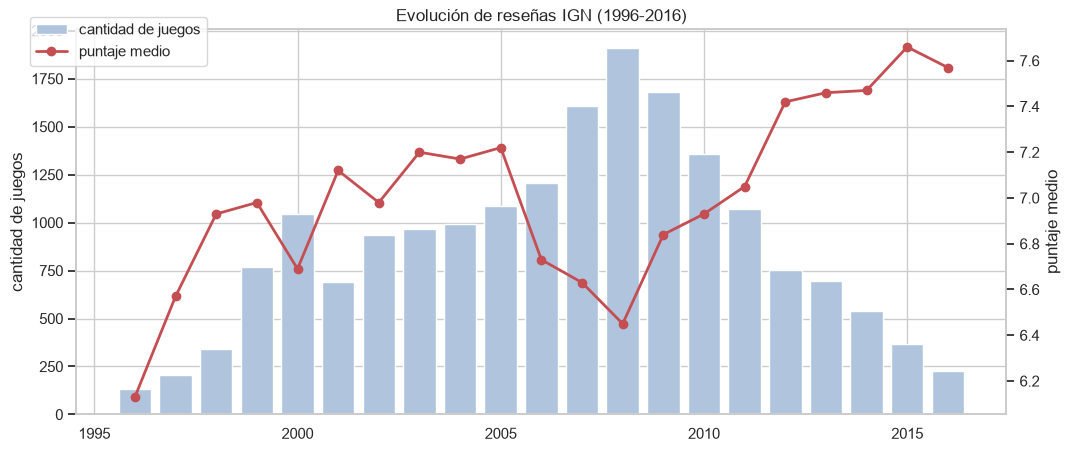

In [29]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(por_anio.index, por_anio["count"], color="#B0C4DE", label="cantidad de juegos")
ax1.set_ylabel("cantidad de juegos")
ax2 = ax1.twinx()
ax2.plot(por_anio.index, por_anio["mean"], color="#C44E52", marker="o", lw=2, label="puntaje medio")
ax2.set_ylabel("puntaje medio"); ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
plt.title("Evolución de reseñas IGN (1996-2016)"); plt.show()

### 3.2 Dispersión año vs puntaje con línea de tendencia

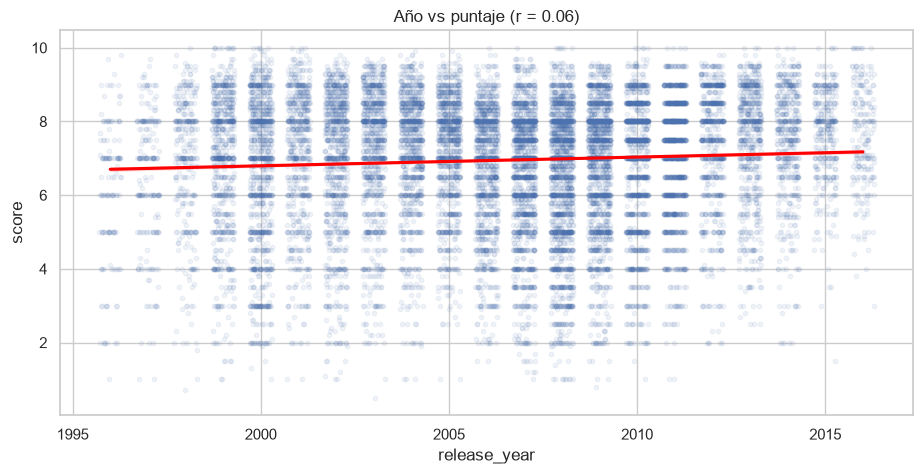

In [30]:
sns.regplot(data=df, x="release_year", y="score", x_jitter=0.3,
            scatter_kws={"alpha": 0.08, "s": 10}, line_kws={"color": "red"})
plt.title(f"Año vs puntaje (r = {r_pearson:.2f})"); plt.show()

### 3.3 Distribución del puntaje por género (boxplot)

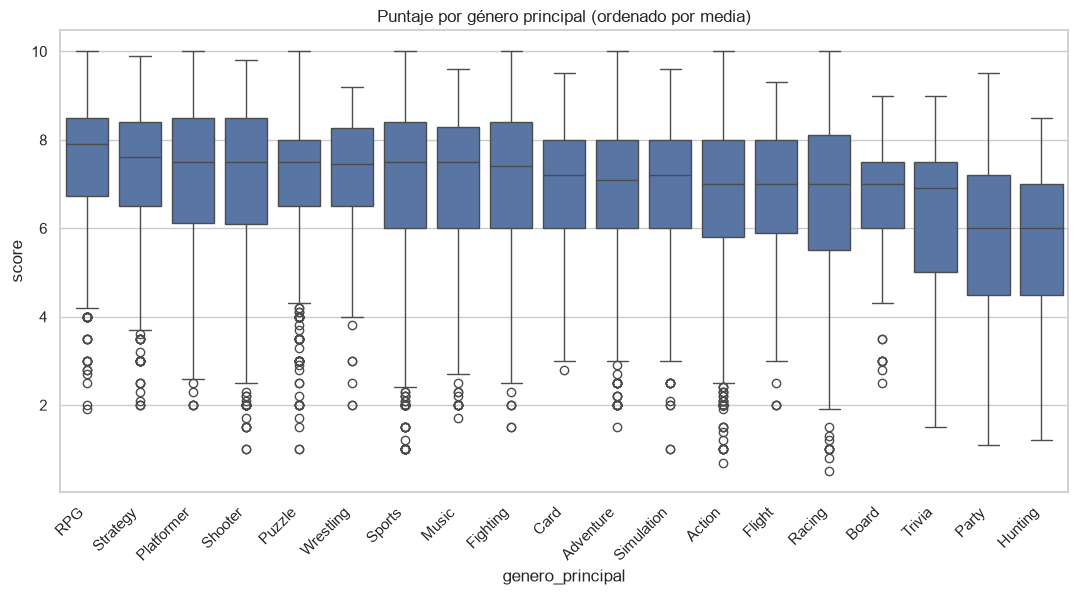

In [31]:
orden = g.index
plt.figure(figsize=(13, 6))
sns.boxplot(data=df[df.genero_principal.isin(top_gen)], x="genero_principal", y="score", order=orden)
plt.xticks(rotation=45, ha="right"); plt.title("Puntaje por género principal (ordenado por media)"); plt.show()

### 3.4 Puntaje medio por plataforma

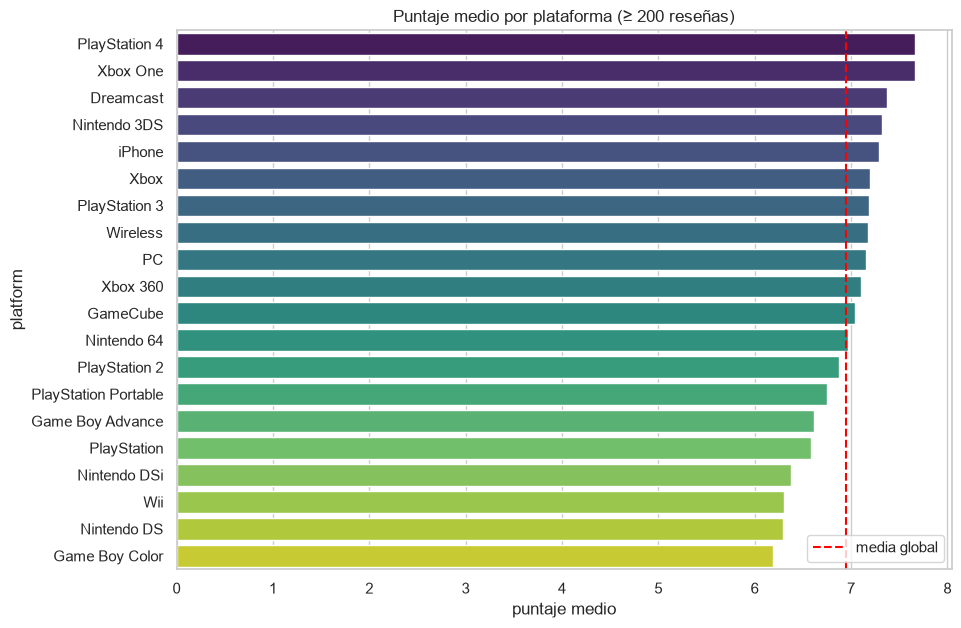

In [32]:
plt.figure(figsize=(10, 7))
sns.barplot(x=p["mean"], y=p.index, hue=p.index, palette="viridis", legend=False)
plt.axvline(df.score.mean(), color="red", ls="--", label="media global")
plt.legend(); plt.title("Puntaje medio por plataforma (≥ 200 reseñas)"); plt.xlabel("puntaje medio"); plt.show()

### 3.5 Mapa de calor: puntaje medio por género y periodo

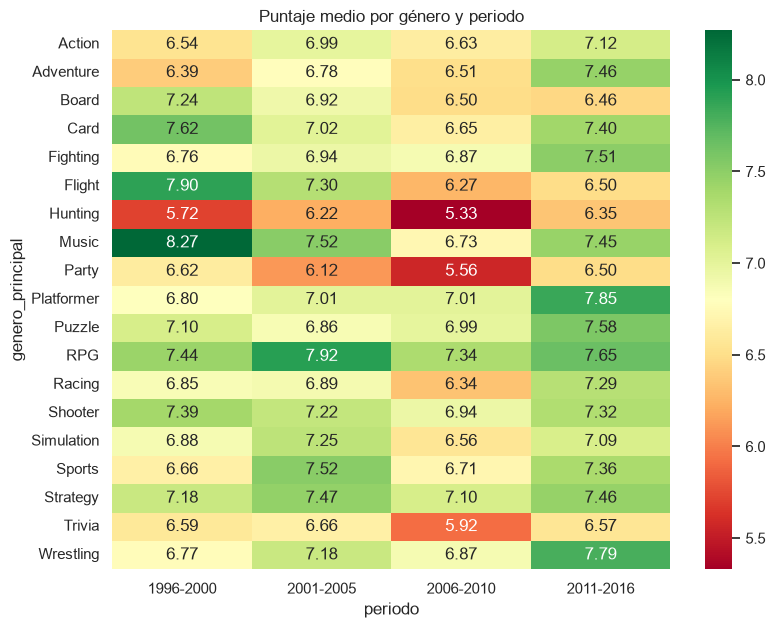

In [33]:
pivot = (df[df.genero_principal.isin(top_gen)]
         .pivot_table(index="genero_principal", columns="periodo", values="score", aggfunc="mean", observed=False)
         .round(2))
plt.figure(figsize=(9, 7))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title("Puntaje medio por género y periodo"); plt.show()

### 3.6 Densidad del puntaje por periodo

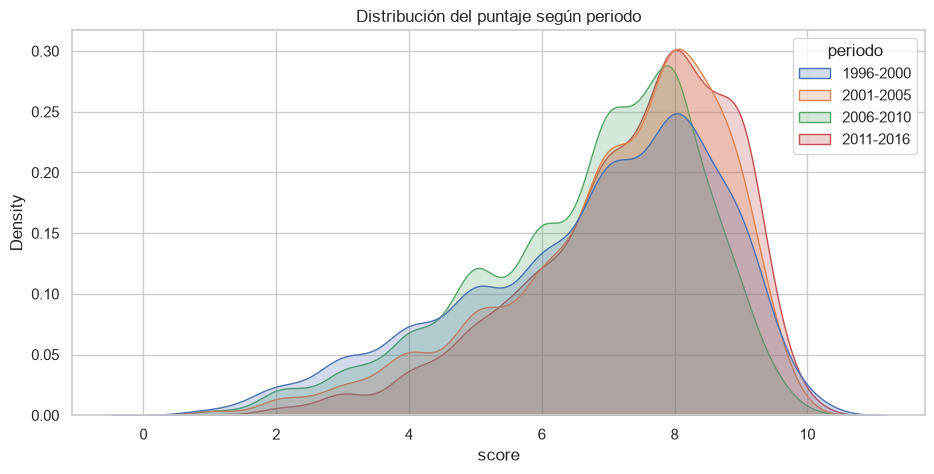

In [34]:
sns.kdeplot(data=df, x="score", hue="periodo", common_norm=False, fill=True, alpha=0.25)
plt.title("Distribución del puntaje según periodo"); plt.show()

### 3.7 Composición de calificaciones por periodo

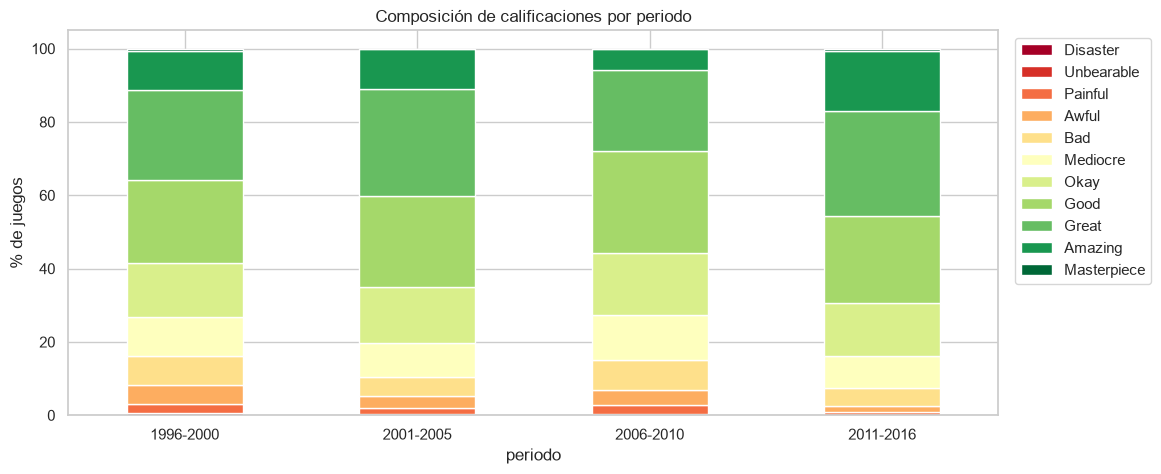

In [35]:
comp = pd.crosstab(df.periodo, df.score_phrase, normalize="index").mul(100)
comp.plot(kind="bar", stacked=True, colormap="RdYlGn", figsize=(12, 5))
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.ylabel("% de juegos")
plt.title("Composición de calificaciones por periodo"); plt.xticks(rotation=0); plt.show()

### Conclusiones generales

1. IGN califica de forma generosa: la nota típica está entre 7 y 8 y las notas bajas son minoría.
2. La calidad percibida cambia con el tiempo de forma no lineal: el *boom* de 2006-2010 (Wii, DS, muchos lanzamientos) trajo más juegos y notas más bajas; desde 2011 hay menos reseñas y mejor valoradas, posiblemente porque IGN reseña menos títulos y más seleccionados.
3. El género influye en la nota: RPG y estrategia destacan; juegos de fiesta, caza y trivia quedan al final.
4. La plataforma también importa: las de generación reciente puntúan más alto y las portátiles o casuales de Nintendo, más bajo.
5. El catálogo cambió de deportes y carreras a shooters, aventuras y RPG.

> Las relaciones encontradas son descriptivas (correlación, no causalidad).

---
## Cómo exportar este notebook a HTML

Desde la terminal, en la carpeta del notebook:

```bash
python -m nbconvert --to html --execute analisis_ign_games.ipynb
```

`--execute` vuelve a ejecutar todas las celdas (consultando Supabase) antes de exportar. Para ocultar el código y dejar solo resultados, se agrega `--no-input`. En Jupyter/VS Code también se puede usar **Archivo → Exportar → HTML**.